# 微调

*迁移学习*（transfer learning）将从*源数据集*学到的知识迁移到*目标数据集*  

### 步骤

1. 在源数据集（例如ImageNet数据集）上预训练神经网络模型，即*源模型*。
1. 创建一个新的神经网络模型，即*目标模型*。这将复制源模型上的所有模型设计及其参数（输出层除外）。我们假定这些模型参数包含从源数据集中学到的知识，这些知识也将适用于目标数据集。我们还假设源模型的输出层与源数据集的标签密切相关；因此不在目标模型中使用该层。
1. 向目标模型添加输出层，其输出数是目标数据集中的类别数。然后随机初始化该层的模型参数。
1. 在目标数据集（如椅子数据集）上训练目标模型。输出层将从头开始进行训练，而所有其他层的参数将根据源模型的参数进行微调。  

当目标数据集比源数据集小得多时，微调有助于提高模型的泛化能力。

In [25]:
%matplotlib inline
import os
import torch
import torchvision
from torch import nn
from d2l import torch as d2l

In [26]:
""" 加载数据 """
# d2l.DATA_HUB['hotdog'] = (d2l.DATA_URL + 'hotdog.zip',
#                          'fba480ffa8aa7e0febbb511d181409f899b9baa5')
# data_dir = d2l.download_extract('hotdog')
data_dir = '..\data\hotdog'

train_imgs = torchvision.datasets.ImageFolder(os.path.join(data_dir, 'train'))
test_imgs = torchvision.datasets.ImageFolder(os.path.join(data_dir, 'test'))

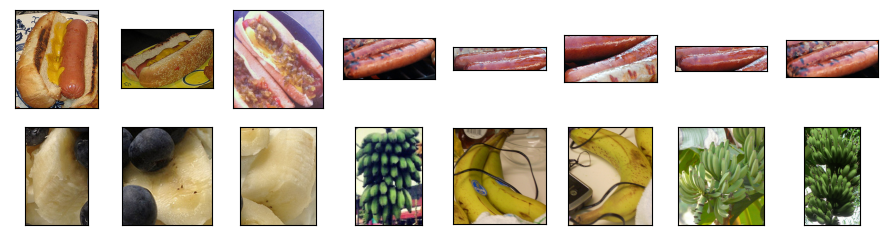

In [27]:
hotdogs = [train_imgs[i][0] for i in range(8)]
not_hotdogs = [train_imgs[-i - 1][0] for i in range(8)]
d2l.show_images(hotdogs + not_hotdogs, 2, 8, scale=1.4);

In [28]:
# 使用RGB通道的均值和标准差，以标准化每个通道
normalize = torchvision.transforms.Normalize(
    [0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

train_augs = torchvision.transforms.Compose([
    torchvision.transforms.RandomResizedCrop(224),
    torchvision.transforms.RandomHorizontalFlip(),
    torchvision.transforms.ToTensor(),
    normalize])

test_augs = torchvision.transforms.Compose([
    torchvision.transforms.Resize([256, 256]),
    torchvision.transforms.CenterCrop(224),
    torchvision.transforms.ToTensor(),
    normalize])

In [29]:
""" 定义和初始化模型 """
from torchvision.models import ResNet18_Weights
import ssl
ssl._create_default_https_context = ssl._create_unverified_context
# 加载预训练模型
finetune_net = torchvision.models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
# 修改输出层
finetune_net.fc = nn.Linear(finetune_net.fc.in_features, 2)
# 初始化输出层参数
nn.init.xavier_uniform_(finetune_net.fc.weight);

In [ ]:
""" 微调模型 """
# 如果param_group=True，输出层中的模型参数将使用十倍的学习率
def train_fine_tuning(net, learning_rate, batch_size=128, num_epochs=5,
                      param_group=True):
    # 数据加载
    train_iter = torch.utils.data.DataLoader(torchvision.datasets.ImageFolder(
        os.path.join(data_dir, 'train'), transform=train_augs),
        batch_size=batch_size, shuffle=True)
    test_iter = torch.utils.data.DataLoader(torchvision.datasets.ImageFolder(
        os.path.join(data_dir, 'test'), transform=test_augs),
        batch_size=batch_size)
    # 获取可用 GPU 
    devices = d2l.try_all_gpus()
    # 损失函数
    loss = nn.CrossEntropyLoss(reduction="none")
    if param_group:
        params_1x = [param for name, param in net.named_parameters()
             if name not in ["fc.weight", "fc.bias"]]
        trainer = torch.optim.SGD([{'params': params_1x},           # 除fc层外的参数
                                   {'params': net.fc.parameters(),  # fc层参数
                                    'lr': learning_rate * 10}],
                                lr=learning_rate, 
                                weight_decay=0.001)     # L2 正则化，防止过拟合。训练数据少时尤其重要
    else:
        trainer = torch.optim.SGD(net.parameters(), lr=learning_rate,
                                  weight_decay=0.001)
    d2l.train_ch13(net, train_iter, test_iter, loss, trainer, num_epochs,
                   devices)

loss 0.174, train acc 0.930, test acc 0.929
458.3 examples/sec on [device(type='cuda', index=0)]


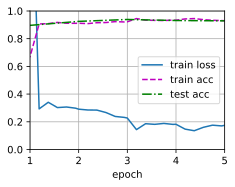

In [31]:
train_fine_tuning(finetune_net, 5e-5)

loss 0.386, train acc 0.836, test acc 0.864
480.0 examples/sec on [device(type='cuda', index=0)]


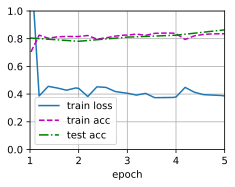

In [32]:
scratch_net = torchvision.models.resnet18()
scratch_net.fc = nn.Linear(scratch_net.fc.in_features, 2)
train_fine_tuning(scratch_net, 5e-4, param_group=False)